# 10.2: Watch the budget (FRED, Consumer Expenditure Survey)

**Issue #10, cycle 2: The hemline index** (Pillar 5, Trend Forecast, With Receipts)

## What this notebook does

If fashion is a signal about the economy, the clearest place to see a downturn is
not in skirt lengths but in what households actually spend on clothes. This notebook
asks: when the economy turned in 2008 and 2020, how did clothing spending change for
households at different income levels?

The main measure is clothing as a share of each group's total spending. It's a ratio,
so changes in prices cancel out and no inflation adjustment is needed.

Note: this issue has no manually sourced prices, so the usual X.2 slot is used for a
second FRED pull instead.

## Data (FRED, from the BLS Consumer Expenditure Survey)

Annual averages per household ("consumer unit"), grouped into five equal-sized income
groups (quintiles) by income before taxes, 1984 to 2024.

| Income group | Clothing ("apparel and services") | Total spending |
|---|---|---|
| Lowest 20% | `CXUAPPARELLB0102M` | `CXUTOTALEXPLB0102M` |
| Second 20% | `CXUAPPARELLB0103M` | `CXUTOTALEXPLB0103M` |
| Middle 20% | `CXUAPPARELLB0104M` | `CXUTOTALEXPLB0104M` |
| Fourth 20% | `CXUAPPARELLB0105M` | `CXUTOTALEXPLB0105M` |
| Highest 20% | `CXUAPPARELLB0106M` | `CXUTOTALEXPLB0106M` |

These are income groups (what households earn in a year), not the wealth groups used
in 10.1 (what households own).

## Outputs

- `data/raw/cycle 2/issue-10/fred_clothing_spending.csv`
- Exploratory charts only. Branded versions are made in Canva.
- Findings (section 4) feed slide 8 (THE FORECAST).

## Notes

- Annual data. FRED dates each year by 1 January (e.g. `2024-01-01` is the 2024 survey year).
- Dollar amounts are not adjusted for inflation. Use them for rough changes only;
  the share of total spending is the measure to rely on.
- Recession shading reuses `recession_periods.csv` from 10.1, so run 10.1 first.
- The FRED API key is read from `.env` and never written into this notebook.

## Limitations

- **Averages, not typical households.** Each figure is the average across every
  household in an income group, including those who spend little on clothes by
  choice. The data can't separate "chose not to" from "couldn't afford to."
- **Lowest income is not the same as poorest.** The lowest-income group includes
  retirees and students with little income in a given year who may be living on
  savings or support.
- **Same group over time is the fairer comparison.** Preferences like disliking
  shopping exist in every group and change slowly, so this notebook compares each
  group with itself before and after a downturn, rather than comparing levels
  between groups.
- **Slow data.** Figures are annual and released months after the year ends (latest:
  2024). They show who a downturn lands on, not that one is coming.
- **Self-reported.** The Consumer Expenditure Survey relies on households reporting
  their own spending, so small changes should be read loosely.

## 1. Setup

Imports, API key and file paths. The notebook sits three folders below the repo root,
so every path starts with `../../../`. The FRED key is read from `.env` and is never
written into this notebook.

In [1]:
# Force the inline backend first, to avoid the Agg backend conflict hit in Issue #4
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")

import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from dotenv import load_dotenv

# Load FRED_API_KEY from the repo-root .env (gitignored)
load_dotenv("../../../.env")
FRED_API_KEY = os.getenv("FRED_API_KEY")
assert FRED_API_KEY, "FRED_API_KEY not found. Check the .env file at the repo root."

# Paths for this issue
RAW_DIR = Path("../../../data/raw/cycle 2/issue-10")
PROCESSED_DIR = Path("../../../data/processed/cycle 2/issue-10")
PALETTE_PATH = Path("../../../brand/palette.json")

# Fail early if the folders from the mkdir step are missing
for folder in (RAW_DIR, PROCESSED_DIR):
    assert folder.exists(), f"Missing folder: {folder}"

## 2. Extracting data from FRED

### 2.1 FRED fetch helper

One function pulls any FRED series into a two-column table (date, value).

Two FRED quirks are handled here:
- A bad series ID returns a JSON error message, not an HTTP error. If the response
  has no "observations", the helper prints FRED's own message before stopping.
- Missing values come back as "." rather than blank, so values are converted to
  numbers with anything unreadable set to empty (NaN).

In [2]:
FRED_URL = "https://api.stlouisfed.org/fred/series/observations"

def fetch_fred(series_id, start="1984-01-01"):
    """Pull one FRED series as a DataFrame with columns: date, <series_id>."""
    params = {
        "series_id": series_id,
        "api_key": FRED_API_KEY,
        "file_type": "json",
        "observation_start": start,
    }
    resp = requests.get(FRED_URL, params=params, timeout=30)
    data = resp.json()

    # FRED reports bad IDs inside the JSON, so show its message before failing
    if "observations" not in data:
        print(data)
        raise KeyError(f"No observations returned for {series_id}")

    df = pd.DataFrame(data["observations"])[["date", "value"]]
    df["date"] = pd.to_datetime(df["date"])
    df["value"] = pd.to_numeric(df["value"], errors="coerce")  # "." becomes NaN
    return df.rename(columns={"value": series_id})

### 2.2 Clothing and total spending by income group

Pull clothing spending and total spending for all five income groups, then work out
clothing as a share of each group's total spending. Only years where every series
has a value are kept.

In [3]:
# Series IDs share a pattern: the two digits before the final "M" pick the income group
QUINTILES = {"02": "lowest_20", "03": "second_20", "04": "middle_20",
             "05": "fourth_20", "06": "highest_20"}

spend = None
for code, label in QUINTILES.items():
    clothes_id = f"CXUAPPARELLB01{code}M"
    total_id = f"CXUTOTALEXPLB01{code}M"
    clothes = fetch_fred(clothes_id).rename(columns={clothes_id: f"{label}_clothes"})
    total = fetch_fred(total_id).rename(columns={total_id: f"{label}_total"})
    both = clothes.merge(total, on="date", how="inner")
    spend = both if spend is None else spend.merge(both, on="date", how="inner")

spend = spend.sort_values("date").reset_index(drop=True)
spend["year"] = spend["date"].dt.year

# Clothing as a % of each group's total spending
for label in QUINTILES.values():
    spend[f"{label}_share"] = (spend[f"{label}_clothes"] / spend[f"{label}_total"] * 100).round(2)

spend.to_csv(RAW_DIR / "fred_clothing_spending.csv", index=False)
print(f"Years: {spend['year'].min()} to {spend['year'].max()}")

# Latest five years of clothing's share of the budget, per income group
print(spend[["year"] + [f"{l}_share" for l in QUINTILES.values()]].tail(5).to_string(index=False))

Years: 1984 to 2024
 year  lowest_20_share  second_20_share  middle_20_share  fourth_20_share  highest_20_share
 2020             2.65             2.16             2.45             2.03              2.46
 2021             3.05             2.74             2.75             2.36              2.58
 2022             2.77             2.55             2.77             2.77              2.57
 2023             2.78             2.55             2.50             2.83              2.59
 2024             3.21             2.65             2.45             2.26              2.58


### 2.3 What happened in each downturn

For each income group, compare the year before each downturn with the lowest year
of clothing spending after it: dollars spent on clothes (not inflation-adjusted, so
rough), and clothing's share of the budget before and in that low year.

In [4]:
# (year before the downturn, years after it to search for the low point)
DOWNTURNS = {"2008": (2007, [2008, 2009, 2010]), "2020": (2019, [2020, 2021])}

by_year = spend.set_index("year")
rows = []
for name, (before, after_years) in DOWNTURNS.items():
    b = by_year.loc[before]
    a = by_year.loc[after_years]
    for label in QUINTILES.values():
        low_year = a[f"{label}_clothes"].idxmin()
        low = a.loc[low_year]
        rows.append({
            "downturn": name,
            "group": label,
            "clothes_before": b[f"{label}_clothes"],
            "clothes_low": low[f"{label}_clothes"],
            "low_year": low_year,
            "clothes_change_pct": round((low[f"{label}_clothes"] / b[f"{label}_clothes"] - 1) * 100, 1),
            "share_before": b[f"{label}_share"],
            "share_low_year": low[f"{label}_share"],
        })

downturns = pd.DataFrame(rows)
print(downturns.to_string(index=False))

downturn      group  clothes_before  clothes_low  low_year  clothes_change_pct  share_before  share_low_year
    2008  lowest_20             765          774      2010                 1.2          3.74            3.69
    2008  second_20            1042         1151      2008                10.5          3.35            3.63
    2008  middle_20            1654         1361      2008               -17.7          3.90            3.19
    2008  fourth_20            2092         1737      2010               -17.0          3.65            3.15
    2008 highest_20            3849         3339      2009               -13.3          3.98            3.54
    2020  lowest_20             818          762      2020                -6.8          2.85            2.65
    2020  second_20            1246          862      2020               -30.8          3.08            2.16
    2020  middle_20            1530         1263      2020               -17.5          2.88            2.45
    2020  fourth_20

In [6]:
# Exact first and latest shares, for the long-run decline in the Findings
share_cols = [f"{l}_share" for l in QUINTILES.values()]
print(spend.set_index("year").loc[[1984, 2024], share_cols].T)

year              1984  2024
lowest_20_share   5.41  3.21
second_20_share   5.55  2.65
middle_20_share   6.52  2.45
fourth_20_share   6.03  2.26
highest_20_share  6.33  2.58


## 3. Plot

Exploratory charts only, to check the shapes before writing slide copy.
Grey bands mark US recessions (from 10.1). Branded versions are made in Canva.

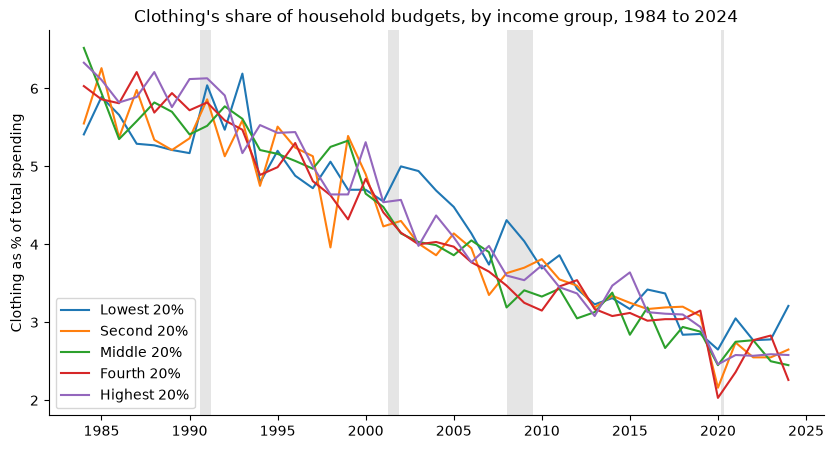

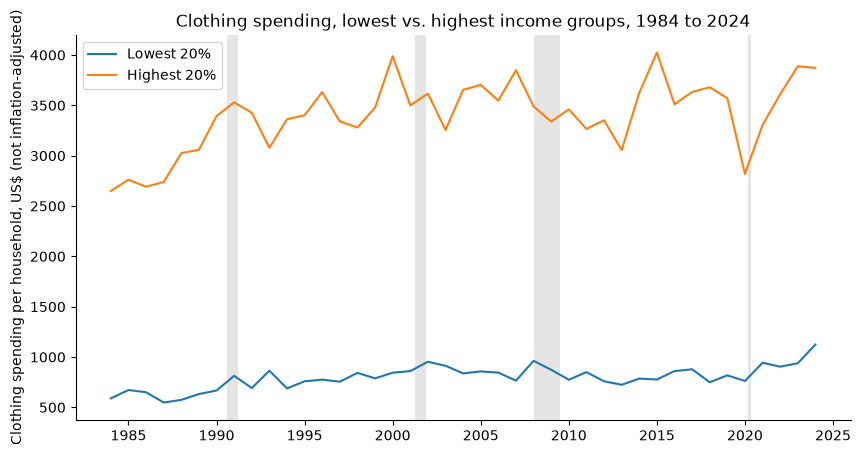

In [5]:
# Recession periods saved by 10.1
recessions = pd.read_csv(PROCESSED_DIR / "recession_periods.csv", parse_dates=["start", "end"])

def shade_recessions(ax, start="1984-01-01"):
    """Grey bands for each recession on a date axis."""
    for _, r in recessions.iterrows():
        if r["end"] >= pd.Timestamp(start):
            ax.axvspan(r["start"], r["end"], color="grey", alpha=0.2, lw=0)

labels = {"lowest_20": "Lowest 20%", "second_20": "Second 20%", "middle_20": "Middle 20%",
          "fourth_20": "Fourth 20%", "highest_20": "Highest 20%"}

# Chart 1: clothing's share of the budget, by income group
fig, ax = plt.subplots(figsize=(10, 5))
for key, name in labels.items():
    ax.plot(spend["date"], spend[f"{key}_share"], label=name)
shade_recessions(ax)
ax.set_ylabel("Clothing as % of total spending")
ax.set_title("Clothing's share of household budgets, by income group, 1984 to 2024")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

# Chart 2: dollars spent on clothes (not inflation-adjusted), lowest vs. highest 20%
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(spend["date"], spend["lowest_20_clothes"], label="Lowest 20%")
ax.plot(spend["date"], spend["highest_20_clothes"], label="Highest 20%")
shade_recessions(ax)
ax.set_ylabel("Clothing spending per household, US$ (not inflation-adjusted)")
ax.set_title("Clothing spending, lowest vs. highest income groups, 1984 to 2024")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 4. Findings

### Long run: clothing takes a smaller slice of every budget
- Clothing's share of total spending fell for every income group, by about 40% to
  60%: from 5.41% to 6.52% in 1984 to 2.26% to 3.21% in 2024. All five groups
  move together.
- The lowest-income group's share fell the least (5.41% to 3.21%, about 41%);
  the middle and fourth groups fell the most (about 62% each). The lowest group's
  2024 figure jumped from 2.78% the year before, so treat the exact gap loosely.
- Differences between income groups are small and noisy: the lines cross often, and
  one-year swings of half a percentage point are common. Single-year comparisons
  are unreliable.
- Consistent with Issue #9: clothing prices stayed flat while overall prices rose.

### Downturns: who cut clothing spending

| Downturn | Group | Dollars, before | Dollars, lowest after | Change | Share before | Share in low year |
|---|---|---|---|---|---|---|
| 2008 | Lowest 20% | 765 | 774 (2010) | +1.2% | 3.74% | 3.69% |
| 2008 | Second 20% | 1,042 | 1,151 (2008) | +10.5% | 3.35% | 3.63% |
| 2008 | Middle 20% | 1,654 | 1,361 (2008) | −17.7% | 3.90% | 3.19% |
| 2008 | Fourth 20% | 2,092 | 1,737 (2010) | −17.0% | 3.65% | 3.15% |
| 2008 | Highest 20% | 3,849 | 3,339 (2009) | −13.3% | 3.98% | 3.54% |
| 2020 | Lowest 20% | 818 | 762 (2020) | −6.8% | 2.85% | 2.65% |
| 2020 | Second 20% | 1,246 | 862 (2020) | −30.8% | 3.08% | 2.16% |
| 2020 | Middle 20% | 1,530 | 1,263 (2020) | −17.5% | 2.88% | 2.45% |
| 2020 | Fourth 20% | 2,245 | 1,463 (2020) | −34.8% | 3.15% | 2.03% |
| 2020 | Highest 20% | 3,571 | 2,820 (2020) | −21.0% | 2.94% | 2.46% |

"Before" is 2007 or 2019. "Lowest after" is the lowest-spending year in 2008 to 2010
or 2020 to 2021. Dollars are not adjusted for inflation.

- In both downturns, the lowest-income group cut clothing spending the least, and
  its share of the budget barely moved. The biggest cuts came from households with
  more room to cut.
- The highest-income group's spending visibly dips in 2008-09 and 2020, then
  rebounds. The lowest-income group's spending is close to flat throughout (in
  nominal dollars, which means it buys less over time as prices rise).

### Possible reasons (not tested here)
- Nothing left to cut: at about $765 to $820 a year, clothing for the lowest-income
  group may already be basics.
- Who's in the group changes: people who lose jobs in a downturn move into the
  lowest-income group and may keep their old spending habits for a while.
- 2020 is a weak test: lockdowns cut spending on going-out clothes regardless of income.

### For the slides
- Slide 8: option (a), "nothing left to cut." Use percentage changes, not dollars.
  Don't claim who started any fashion trend; this data doesn't show that.
- If the dollars chart is used, label it "not adjusted for inflation," or limit it to
  2005 to 2024.